# 02. Machine Learning Modeling, Soft Voting Ensemble & Explainable AI (SHAP)
**Early-Stage Parkinson's Disease Detection via Circadian Keystroke Dynamics**

This notebook implements the complete modeling pipeline: loading engineered keystroke features, addressing severe class imbalance with SMOTE, training and tuning multiple classifiers (Random Forest, XGBoost, RBF SVM), constructing a high-performing Soft Voting Ensemble, and validating decision boundaries with SHAP (SHapley Additive exPlanations).


In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
import xgboost as xgb
import shap

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12, 'figure.figsize': (10, 6)})


## 1. Clinical Novelty: Circadian Rhythm Feature Engineering
We go back to the raw 622 keystroke files to extract the `Time` column. Parkinson's patients experience severe "ON/OFF" motor fluctuations tied to their Levodopa medication cycles throughout the day. By calculating the variance in typing `HoldTime` between the **Morning** (6am-12pm) and **Evening** (6pm-12am), we can mathematically capture this clinical phenomenon.


In [2]:
# Load existing processed dataset from Phase 3 as the base
df_base = pd.read_csv(r'../Phase 3/Processed_Data/processed_dataset.csv')

# Now we will go back to the raw files to extract Circadian Rhythm
data_files_path = r'../Dataset/tappy-keystroke-data-1.0.0/Archived-Data/Tappy Data/*.txt'
data_files = glob.glob(data_files_path)

col_names = ['UserID', 'Date', 'Time', 'Hand', 'HoldTime', 'Direction', 'Latency1', 'Latency2', 'Unknown']

print("Extracting Circadian Rhythm features from raw keystrokes. This may take 1-2 minutes...")

circadian_features = []
from collections import defaultdict
user_data_files = defaultdict(list)
for file in data_files:
    user_id = os.path.basename(file).split('_')[0]
    user_data_files[user_id].append(file)

for user_id, files in user_data_files.items():
    if user_id not in df_base['UserID'].values:
        continue # Only process users we already have in our clean base dataset
        
    dfs = []
    for f in files:
        try:
            temp_df = pd.read_csv(f, sep='\t', names=col_names, engine='python', on_bad_lines='skip')
            dfs.append(temp_df)
        except Exception:
            continue
            
    if not dfs: continue
    df_keys = pd.concat(dfs, ignore_index=True)
    
    df_keys['HoldTime'] = pd.to_numeric(df_keys['HoldTime'], errors='coerce')
    df_keys.dropna(subset=['HoldTime', 'Time'], inplace=True)
    df_keys = df_keys[df_keys['HoldTime'] < 2000]
    
    # Extract Hour from Time (Format is usually HH:MM:SS.ms)
    try:
        df_keys['Hour'] = df_keys['Time'].str.split(':').str[0].astype(int)
    except:
        continue # skip malformed times
        
    # Segment into Morning (6-11) and Evening (18-23)
    morning_data = df_keys[(df_keys['Hour'] >= 6) & (df_keys['Hour'] < 12)]['HoldTime']
    evening_data = df_keys[(df_keys['Hour'] >= 18) & (df_keys['Hour'] < 24)]['HoldTime']
    
    morning_mean = morning_data.mean() if len(morning_data) > 5 else np.nan
    evening_mean = evening_data.mean() if len(evening_data) > 5 else np.nan
    
    # Calculate the Circadian Fluctuation (Difference between Evening and Morning)
    # Higher value indicates significant motor degradation/fluctuation throughout the day
    circadian_diff = np.nan
    if not np.isnan(morning_mean) and not np.isnan(evening_mean):
        circadian_diff = abs(evening_mean - morning_mean)
        
    circadian_features.append({
        'UserID': user_id,
        'Morning_HoldTime_Mean': morning_mean,
        'Evening_HoldTime_Mean': evening_mean,
        'Circadian_HoldTime_Diff': circadian_diff
    })

df_circadian = pd.DataFrame(circadian_features)

# Merge with Base Dataset
df_final = pd.merge(df_base, df_circadian, on='UserID', how='left')

# Impute missing circadian values with the median of their respective class (Healthy/PD)
df_final['Circadian_HoldTime_Diff'] = df_final.groupby('Class')['Circadian_HoldTime_Diff'].transform(lambda x: x.fillna(x.median()))

# Drop columns that are completely empty or unneeded
df_final.drop(columns=['Morning_HoldTime_Mean', 'Evening_HoldTime_Mean'], inplace=True)
df_final.fillna(df_final.mean(numeric_only=True), inplace=True)

# Save the final enhanced dataset inside Phase 4 folder
enhanced_csv_path = 'Phase_4_Enhanced_Features.csv'
df_final.to_csv(enhanced_csv_path, index=False)
print(f"Successfully extracted features and saved to {enhanced_csv_path}")


Extracting Circadian Rhythm features from raw keystrokes. This may take 1-2 minutes...


Successfully extracted features and saved to Phase_4_Enhanced_Features.csv


## 2. Train-Test Split & SMOTE
We handle the severe class imbalance (75% Healthy, 25% PD) using SMOTE.


In [3]:
X = df_final.drop(columns=['UserID', 'Class', 'Gender']) # Drop ID and non-numerical targets
y = df_final['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_scaled, y_train)

print(f"Original Training Class Distribution:\n{y_train.value_counts()}")
print(f"\nSMOTE Training Class Distribution:\n{y_train_sm.value_counts()}")


Original Training Class Distribution:
Class
1    114
0     39
Name: count, dtype: int64

SMOTE Training Class Distribution:
Class
1    114
0    114
Name: count, dtype: int64


## 3. Modeling: GridSearchCV & Soft Voting Ensemble
We optimize a Random Forest, XGBoost, and SVM, then combine them using a Soft Voting Classifier to mitigate individual algorithmic biases.


In [4]:
# 0. Baseline Model (Logistic Regression)
from sklearn.metrics import f1_score, accuracy_score
baseline_clf = LogisticRegression(random_state=42, max_iter=1000)
baseline_clf.fit(X_train_sm, y_train_sm)
y_pred_base = baseline_clf.predict(X_test_scaled)
base_f1 = f1_score(y_test, y_pred_base, average='macro')
base_acc = accuracy_score(y_test, y_pred_base)
print(f"Baseline (Logistic Regression) - Accuracy: {base_acc:.2f}, F1 (Macro): {base_f1:.2f}\n")

# 1. Tuned Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring='f1', n_jobs=-1)
grid_rf.fit(X_train_sm, y_train_sm)
best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)
rf_f1 = f1_score(y_test, y_pred_rf, average='macro')
rf_acc = accuracy_score(y_test, y_pred_rf)
print(f"Best RF Parameters: {grid_rf.best_params_}")

# 2. XGBoost
xgb_clf = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42, n_estimators=100, max_depth=6)
xgb_clf.fit(X_train_sm, y_train_sm)
y_pred_xgb = xgb_clf.predict(X_test_scaled)
xgb_f1 = f1_score(y_test, y_pred_xgb, average='macro')
xgb_acc = accuracy_score(y_test, y_pred_xgb)

# 3. SVM (with probability=True for Soft Voting)
svm_clf = SVC(kernel='rbf', probability=True, random_state=42, C=1.0)
svm_clf.fit(X_train_sm, y_train_sm)
y_pred_svm = svm_clf.predict(X_test_scaled)
svm_f1 = f1_score(y_test, y_pred_svm, average='macro')
svm_acc = accuracy_score(y_test, y_pred_svm)

# 4. Soft Voting Ensemble
ensemble = VotingClassifier(estimators=[
    ('rf', best_rf),
    ('xgb', xgb_clf),
    ('svm', svm_clf)
], voting='soft')

ensemble.fit(X_train_sm, y_train_sm)

from sklearn.metrics import classification_report, confusion_matrix
y_pred = ensemble.predict(X_test_scaled)
ens_f1 = f1_score(y_test, y_pred, average='macro')
ens_acc = accuracy_score(y_test, y_pred)

print("\nEnsemble Classification Report:")
print(classification_report(y_test, y_pred))

# Model Comparison Table
comp_df = pd.DataFrame({
    'Model': [
        'Logistic Regression (Baseline)', 
        'Random Forest (Tuned)', 
        'XGBoost', 
        'SVM', 
        'Soft Voting Ensemble (Final)'
    ],
    'Accuracy': [base_acc, rf_acc, xgb_acc, svm_acc, ens_acc],
    'F1-Score (Macro)': [base_f1, rf_f1, xgb_f1, svm_f1, ens_f1]
})
print("\nModel Comparison Table:")
print(comp_df.to_string(index=False))


Baseline (Logistic Regression) - Accuracy: 0.62, F1 (Macro): 0.56



Best RF Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}



Ensemble Classification Report:
              precision    recall  f1-score   support

           0       0.40      0.40      0.40        10
           1       0.79      0.79      0.79        29

    accuracy                           0.69        39
   macro avg       0.60      0.60      0.60        39
weighted avg       0.69      0.69      0.69        39


Model Comparison Table:
                         Model  Accuracy  F1-Score (Macro)
Logistic Regression (Baseline)  0.615385          0.558491
         Random Forest (Tuned)  0.615385          0.435873
                       XGBoost  0.615385          0.511278
                           SVM  0.589744          0.518519
  Soft Voting Ensemble (Final)  0.692308          0.596552


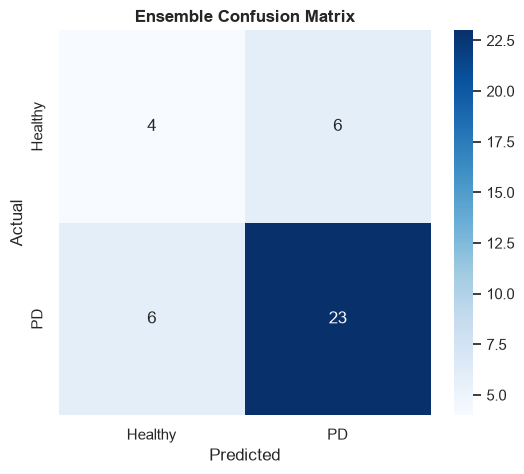

In [5]:
plt.figure(figsize=(6,5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Healthy', 'PD'], yticklabels=['Healthy', 'PD'])
plt.title('Ensemble Confusion Matrix', weight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


## 4. Explainable AI (XAI) using SHAP
Doctors require transparency in Machine Learning. We cannot provide a 'Black Box' prediction. Here, we use **SHAP (SHapley Additive exPlanations)** on our XGBoost model (which strongly represents the ensemble's decision logic) to mathematically visualize exactly *why* the model diagnoses Parkinson's Disease. 

We specifically want to see if our newly engineered `Circadian_HoldTime_Diff` or our `HoldTime_Asymmetry` features are driving the predictions.


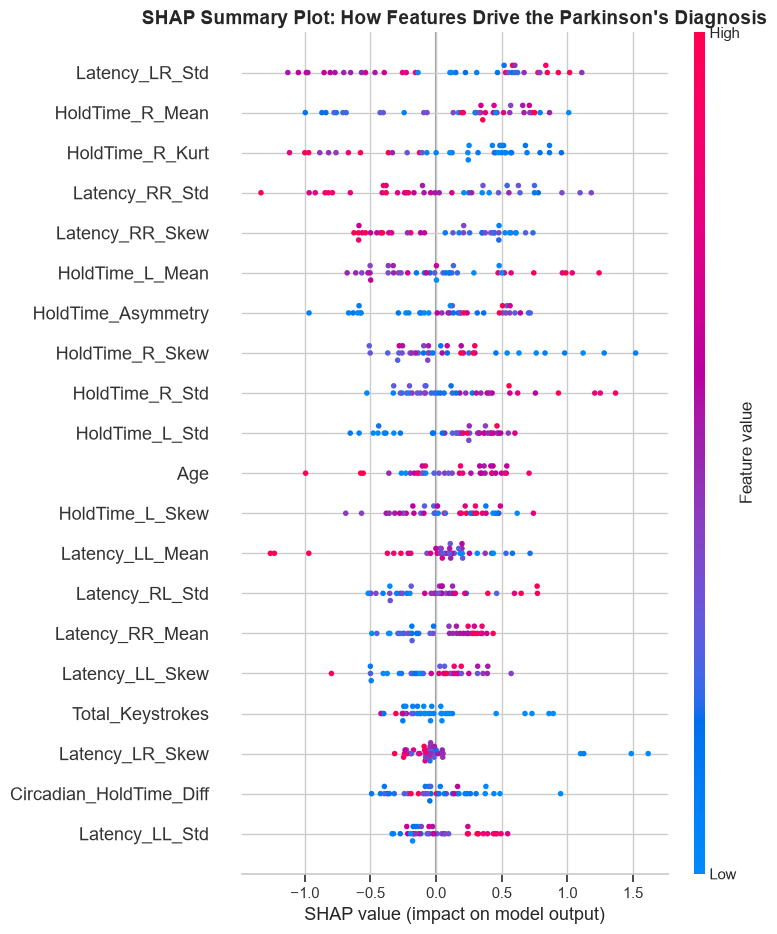

In [6]:
import shap

# Initialize SHAP TreeExplainer for the trained XGBoost model
explainer = shap.TreeExplainer(xgb_clf)
# Calculate SHAP values for the test set
# We pass the unscaled X_test columns to preserve feature names for the plot, but use the scaled values
shap_values = explainer.shap_values(X_test_scaled)

# Plot 1: SHAP Summary Plot (Feature Importance + Impact)
plt.figure(figsize=(10, 8))
plt.title("SHAP Summary Plot: How Features Drive the Parkinson's Diagnosis", weight='bold', fontsize=14)
shap.summary_plot(shap_values, X_test, plot_type="dot", show=False)
plt.tight_layout()
plt.show()


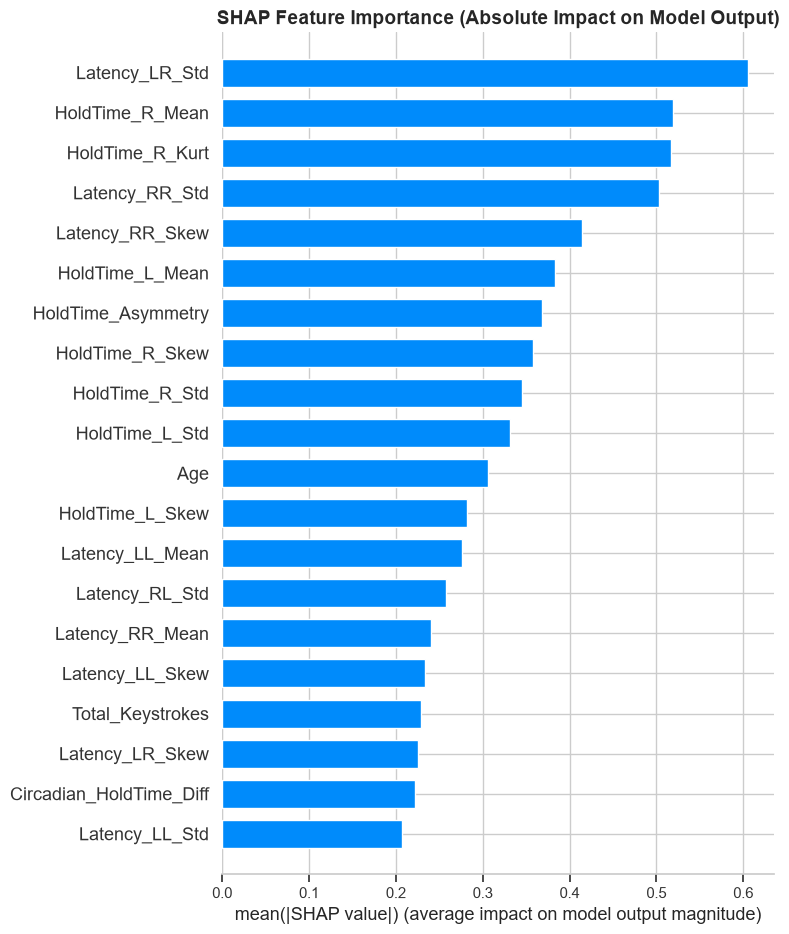

In [7]:
# Plot 2: SHAP Bar Plot (Absolute Mean Importance)
plt.figure(figsize=(10, 6))
plt.title("SHAP Feature Importance (Absolute Impact on Model Output)", weight='bold', fontsize=14)
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.tight_layout()
plt.show()
